# **Project Title**
# Walmart Capstone Project

**Author: Ashwin Vishwakarma**

# **Problem Statement**

A retail store that has multiple outlets across the country are facing issues in managing the
inventory - to match the demand with respect to supply.

# **Data Information**

* Store number

* Week of Sales    

* Sales for the given store in that week

* If it is a holiday week

* Temperature on the day of the sale

* Cost of the fuel in the region

* Consumer Price Index

* Unemployment Rate

# **Tools & Libraries**

* Pandas
* Numpy
* Matplotlib
* Plotly
* Time Series

# **Import libraries**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# **Data Loading**

In [2]:
df = pd.read_csv("Walmart DataSet.csv")

In [3]:
df

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106
...,...,...,...,...,...,...,...,...
6430,45,28-09-2012,713173.95,0,64.88,3.997,192.013558,8.684
6431,45,05-10-2012,733455.07,0,64.89,3.985,192.170412,8.667
6432,45,12-10-2012,734464.36,0,54.47,4.000,192.327265,8.667
6433,45,19-10-2012,718125.53,0,56.47,3.969,192.330854,8.667


# **Data Cleaning**

In [4]:
df.shape

(6435, 8)

In [5]:
df.isnull().sum()

Store           0
Date            0
Weekly_Sales    0
Holiday_Flag    0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
dtype: int64

Observation:
No missing values were found in the dataset. Therefore, no missing value treatment was required.

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Store         6435 non-null   int64  
 1   Date          6435 non-null   object 
 2   Weekly_Sales  6435 non-null   float64
 3   Holiday_Flag  6435 non-null   int64  
 4   Temperature   6435 non-null   float64
 5   Fuel_Price    6435 non-null   float64
 6   CPI           6435 non-null   float64
 7   Unemployment  6435 non-null   float64
dtypes: float64(5), int64(2), object(1)
memory usage: 402.3+ KB


Date column is stored as an object type instead of datetime. Since time-series analysis requires datetime format, I will convert this column to datetime using pandas.

In [7]:
# Convert date
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)

# Sort data
df = df.sort_values(by='Date')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Store         6435 non-null   int64         
 1   Date          6435 non-null   datetime64[ns]
 2   Weekly_Sales  6435 non-null   float64       
 3   Holiday_Flag  6435 non-null   int64         
 4   Temperature   6435 non-null   float64       
 5   Fuel_Price    6435 non-null   float64       
 6   CPI           6435 non-null   float64       
 7   Unemployment  6435 non-null   float64       
dtypes: datetime64[ns](1), float64(5), int64(2)
memory usage: 452.5 KB


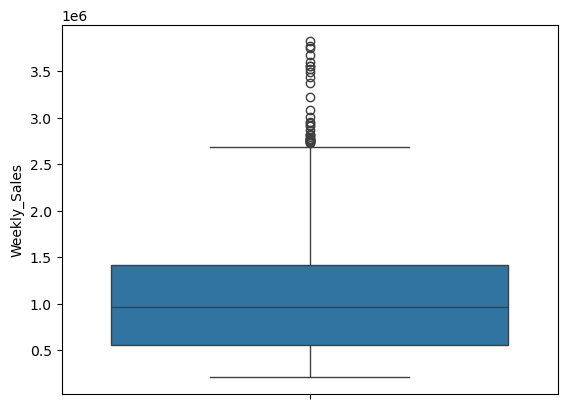

In [9]:
import seaborn as sns

sns.boxplot(df['Weekly_Sales'])
plt.show()

Observation:
The boxplot shows the presence of extreme values in Weekly_Sales. However, since Walmart sales may naturally spike during holidays and seasonal demand, these high values may represent valid business behavior rather than errors. Therefore, outliers were interpreted carefully.

#Feature Engineering

In [10]:
df['Year'] = df['Date'].dt.year
df['Week'] = df['Date'].dt.isocalendar().week.astype(int)

#EDA (Exploratory Data Analysis)

<Axes: xlabel='Unemployment', ylabel='Weekly_Sales'>

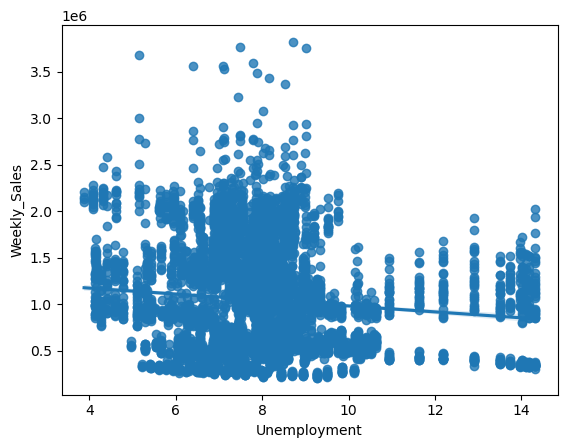

In [11]:
import seaborn as sns
sns.regplot(x='Unemployment', y='Weekly_Sales', data=df)

Insight:

If downward trend → higher unemployment = lower sales

#Store-wise impact:

Lowest correlation stores = most affected

In [12]:
store_unemp = df.groupby('Store')[['Weekly_Sales','Unemployment']].corr().iloc[0::2,-1]
print(store_unemp.sort_values())

Store              
38     Weekly_Sales   -0.785290
44     Weekly_Sales   -0.780076
39     Weekly_Sales   -0.384681
42     Weekly_Sales   -0.356355
41     Weekly_Sales   -0.350630
4      Weekly_Sales   -0.337015
17     Weekly_Sales   -0.263600
3      Weekly_Sales   -0.230413
37     Weekly_Sales   -0.221287
5      Weekly_Sales   -0.207043
43     Weekly_Sales   -0.201954
9      Weekly_Sales   -0.191534
13     Weekly_Sales   -0.171633
7      Weekly_Sales   -0.165382
40     Weekly_Sales   -0.112528
32     Weekly_Sales   -0.099455
1      Weekly_Sales   -0.097955
20     Weekly_Sales   -0.095341
23     Weekly_Sales   -0.077169
16     Weekly_Sales   -0.070864
26     Weekly_Sales   -0.066899
31     Weekly_Sales   -0.064738
8      Weekly_Sales   -0.052580
11     Weekly_Sales   -0.020339
27     Weekly_Sales   -0.014275
24     Weekly_Sales   -0.012261
12     Weekly_Sales   -0.009286
25     Weekly_Sales   -0.004958
45     Weekly_Sales   -0.004041
34     Weekly_Sales    0.017010
22     Weekly_Sales 

##Seasonal Trend

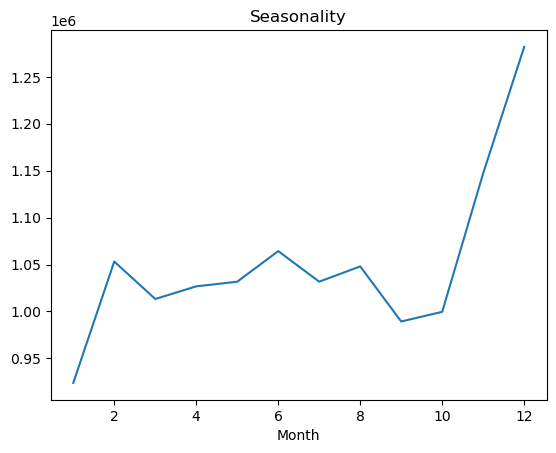

In [13]:
df['Month'] = df['Date'].dt.month

monthly_sales = df.groupby('Month')['Weekly_Sales'].mean()

monthly_sales.plot(kind='line', title='Seasonality')
plt.show()

Insight:

High sales in Nov–Dec →  Holidays (Christmas, Black Friday)

#Temperature Effect

C:\Users\Ashwin\AppData\Local\Temp\ipykernel_17164\1095270480.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  temp_sales = df.groupby('Temp_Bin')['Weekly_Sales'].mean()


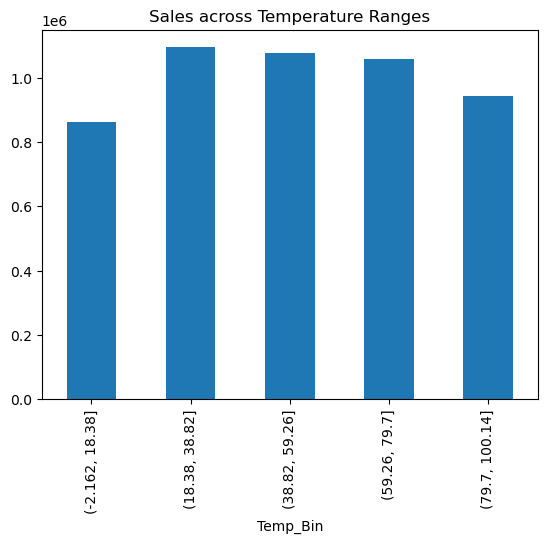

In [14]:
df['Temp_Bin'] = pd.cut(df['Temperature'], bins=5)

temp_sales = df.groupby('Temp_Bin')['Weekly_Sales'].mean()

temp_sales.plot(kind='bar')
plt.title("Sales across Temperature Ranges")
plt.show()

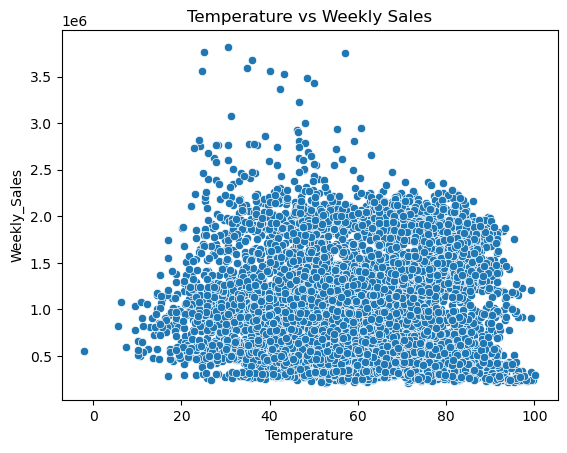

In [15]:
import seaborn as sns
sns.scatterplot(x='Temperature', y='Weekly_Sales', data=df)
plt.title("Temperature vs Weekly Sales")
plt.show()

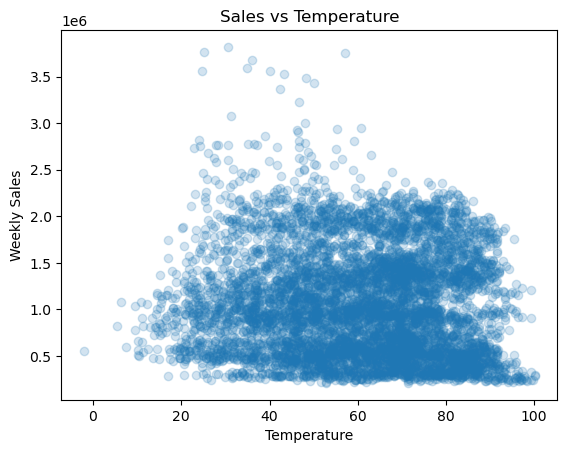

In [16]:
plt.scatter(df['Temperature'], df['Weekly_Sales'], alpha=0.2)
plt.xlabel("Temperature")
plt.ylabel("Weekly Sales")
plt.title("Sales vs Temperature")
plt.show()

Insight:

Weak relationship usually
Extreme temperatures may reduce store visits

#CPI Effect

<Axes: xlabel='CPI', ylabel='Weekly_Sales'>

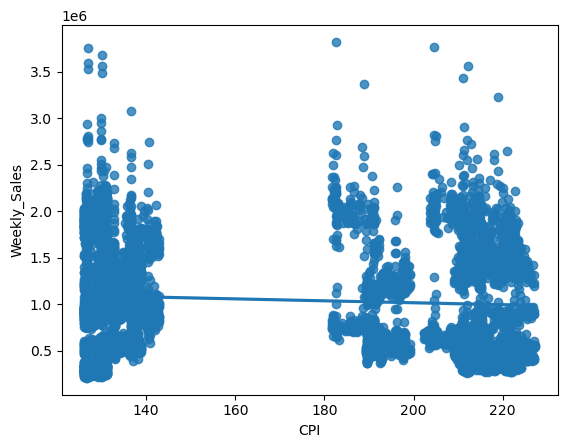

In [17]:
sns.regplot(x='CPI', y='Weekly_Sales', data=df)

Insight:

CPI (increase) --> inflation (increase) --> purchasing power (dicreases)

Insight:

Some stores react more to CPI changes
Helps answer: which stores are sensitive to inflation

#Top Performing Stores

In [18]:
top_stores = df.groupby('Store')['Weekly_Sales'].sum().sort_values(ascending=False)
print(top_stores.head())

Store
20    3.013978e+08
4     2.995440e+08
14    2.889999e+08
13    2.865177e+08
2     2.753824e+08
Name: Weekly_Sales, dtype: float64


#Worst Performing Store And Difference between Highest and lowest performing store

In [19]:
best = top_stores.max()
worst = top_stores.min()

print("Best Store Sales:", best)
print("Worst Store Sales:", worst)
print("Difference:", best - worst)

Best Store Sales: 301397792.46
Worst Store Sales: 37160221.96
Difference: 264237570.49999997


#Correlation Heatmap

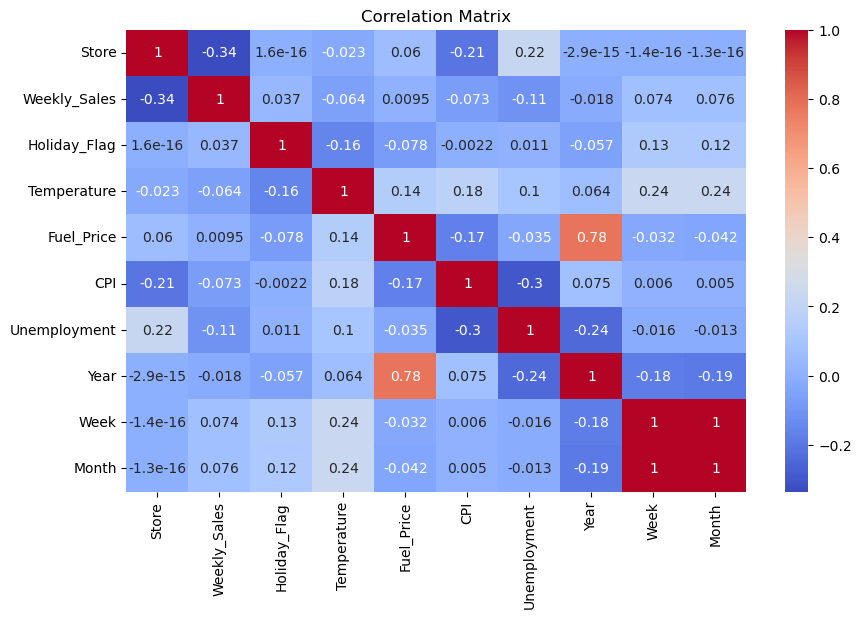

In [20]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(10,6))
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

#Model Building (Forecasting)

Random Forest Model

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

X = df[['Store','Holiday_Flag','Temperature','Fuel_Price','CPI','Unemployment','Year','Week']]
y = df['Weekly_Sales']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

model = RandomForestRegressor()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

#Forecast Next 12 Weeks

In [22]:
future = X_test.tail(12)
future_pred = model.predict(future)

print(future_pred)

[ 630797.2641  893469.8014  327015.1338 1967323.2121  512796.2979
 1031746.4885  687746.1588  433206.1252  929694.0726 2027791.4064
  916607.2102 1146291.2874]


#TIME SERIES

In [23]:
#Prepare the data
store1 = df[df['Store'] == 1].set_index('Date')
ts = store1['Weekly_Sales']

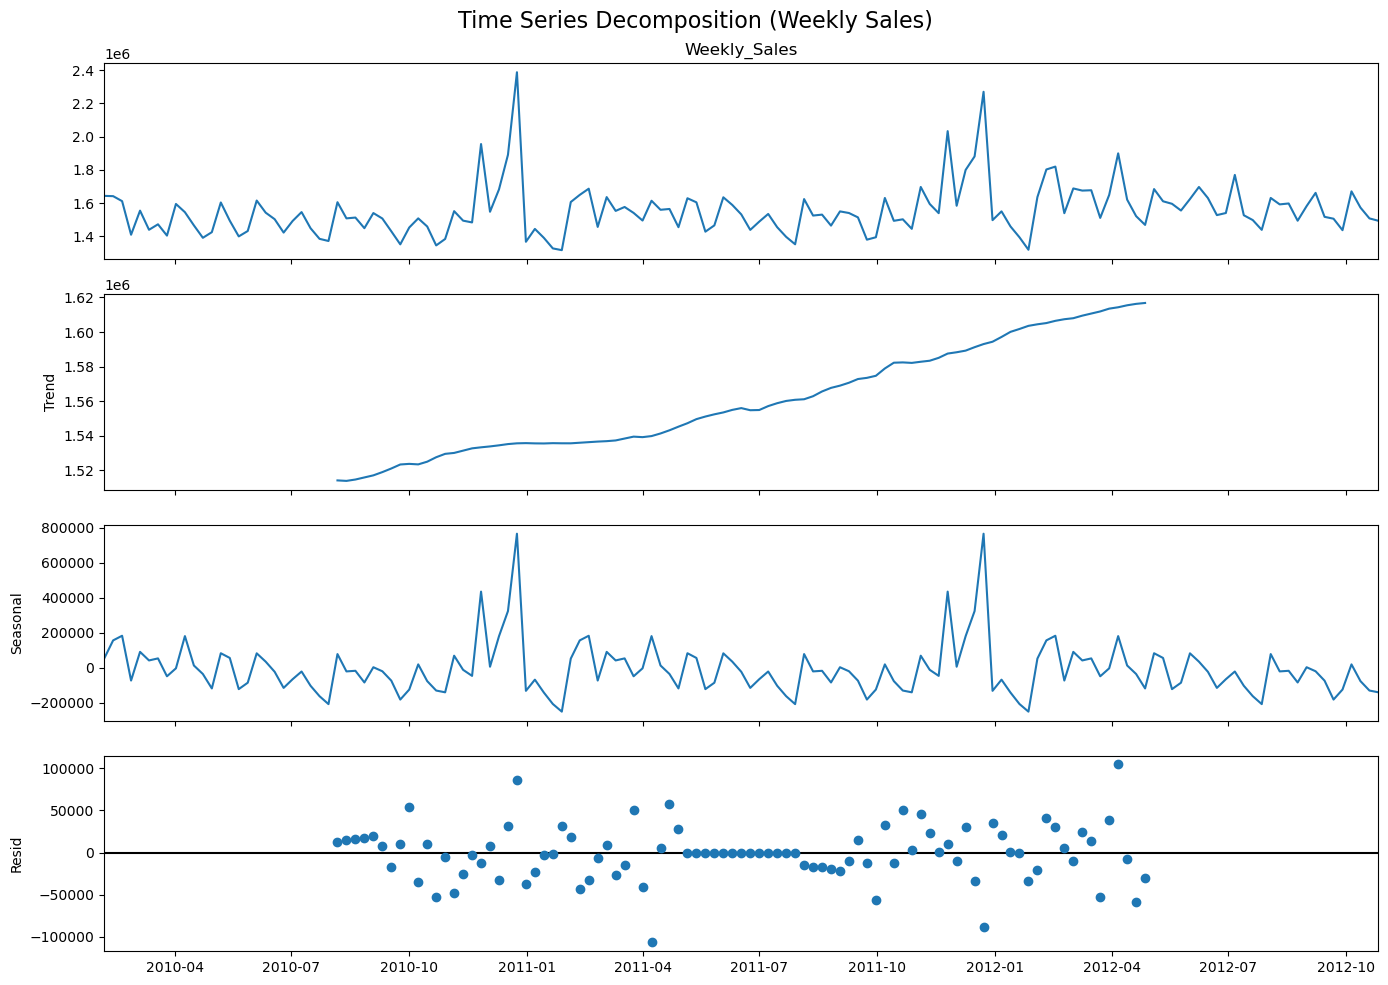

In [24]:
#Decomposition

from statsmodels.tsa.seasonal import seasonal_decompose

# Decompose
decomp = seasonal_decompose(ts, model='additive', period=52)


fig = decomp.plot()

fig.set_size_inches(14, 10)
plt.suptitle("Time Series Decomposition (Weekly Sales)", fontsize=16)

plt.tight_layout()
plt.show()

In [25]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

model = SARIMAX(ts, order=(1,1,1), seasonal_order=(1,1,1,52))
model_fit = model.fit()

C:\Users\Ashwin\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ashwin\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-FRI will be used.
  self._init_dates(dates, freq)
C:\Users\Ashwin\anaconda3\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:866: UserWarning: Too few observations to estimate starting parameters for seasonal ARMA. All parameters except for variances will be set to zeros.
  warn('Too few observations to estimate starting parameters%s.'
C:\Users\Ashwin\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


#Forecast

In [26]:
forecast = model_fit.forecast(steps=12)
print(forecast)

2012-11-02    1.699626e+06
2012-11-09    1.615772e+06
2012-11-16    1.571593e+06
2012-11-23    1.986683e+06
2012-11-30    1.610340e+06
2012-12-07    1.787393e+06
2012-12-14    1.863519e+06
2012-12-21    2.197818e+06
2012-12-28    1.531834e+06
2013-01-04    1.578002e+06
2013-01-11    1.504481e+06
2013-01-18    1.455060e+06
Freq: W-FRI, Name: predicted_mean, dtype: float64


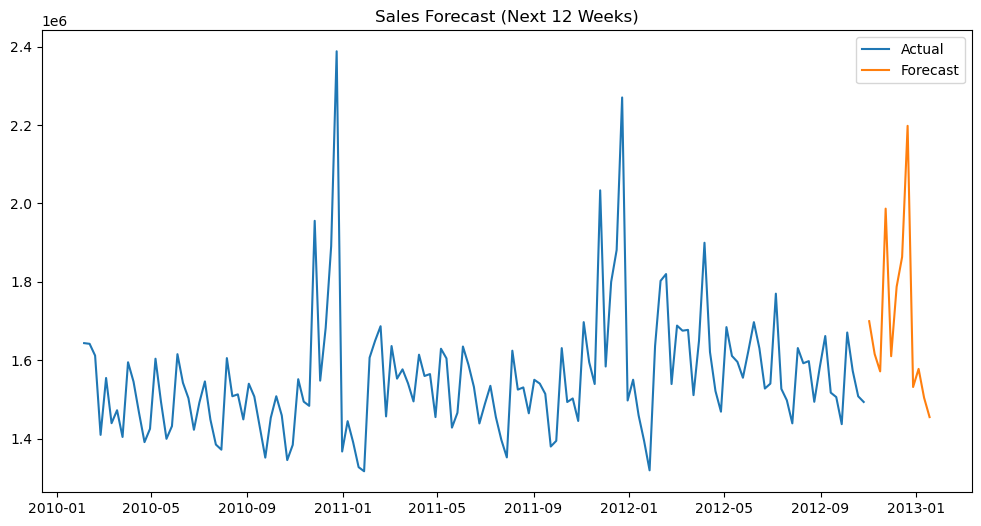

In [27]:
plt.figure(figsize=(12,6))

plt.plot(ts, label='Actual')
plt.plot(forecast, label='Forecast')

plt.legend()
plt.title("Sales Forecast (Next 12 Weeks)")
plt.show()

#Prophet Model

In [28]:
from prophet import Prophet

df_p = df[['Date','Weekly_Sales']]
df_p.columns = ['ds','y']

model = Prophet()
model.fit(df_p)

future = model.make_future_dataframe(periods=12, freq='W')
forecast = model.predict(future)

forecast[['ds','yhat']].tail(12)

16:16:37 - cmdstanpy - INFO - Chain [1] start processing
16:16:41 - cmdstanpy - INFO - Chain [1] done processing


,ds,yhat
143,2012-10-28,1.009238e+06
144,2012-11-04,1.056916e+06
145,2012-11-11,1.122757e+06
146,2012-11-18,1.171047e+06
147,2012-11-25,1.205506e+06
148,2012-12-02,1.265810e+06
149,2012-12-09,1.365880e+06
150,2012-12-16,1.448306e+06
151,2012-12-23,1.422210e+06
152,2012-12-30,1.257318e+06


#Final Insights
Sales peak during holidays

Unemployment negatively affects sales

CPI slight negative

Temperature minimal effect

Large gap between stores